<a href="https://colab.research.google.com/github/SaniaThabassum/SDAV-programs/blob/main/cpd_code_p3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
np.random.seed(42)

In [2]:
x = np.linspace(-4, 4, 400)
std_normal = stats.norm(0,1) # 0-mean, 1-SD

In [8]:
# 68-95-99.7 Rule check
print('68-95-99.7 Rule: ')
print(f'P(-1<Z<1) = {(std_normal.cdf(1)-std_normal.cdf(-1))*100:.6f} %')
print(f'P(-2<Z<2) = {(std_normal.cdf(2)-std_normal.cdf(-2))*100:.6f} %')
print(f'P(-3<Z<3) = {(std_normal.cdf(3)-std_normal.cdf(-3))*100:.6f} %')

68-95-99.7 Rule: 
P(-1<Z<1) = 68.268949 %
P(-2<Z<2) = 95.449974 %
P(-3<Z<3) = 99.730020 %


In [10]:
# Z-score standardization
mu_exam, sigma_exam = 70, 10
for score in [60, 70, 80, 90]:
  z = (score - mu_exam)/sigma_exam
  pct = std_normal.cdf(z) * 100
  print(f' Score = {score} : Z = {z:.2f}, Percentile = {pct:.1f}%')

 Score = 60 : Z = -1.00, Percentile = 15.9%
 Score = 70 : Z = 0.00, Percentile = 50.0%
 Score = 80 : Z = 1.00, Percentile = 84.1%
 Score = 90 : Z = 2.00, Percentile = 97.7%


In [12]:
#----EPONENTIAL DISTRIBUTION----
lam = 1.0
exp_dist = stats.expon(scale=1/lam)
print(f'Exp(lambda=1): Mean = {exp_dist.mean():.4f}, Var = {exp_dist.var():.4f}, SD = {exp_dist.std():.4f}')

# Memoryless Property
print(f' P(X>2)      = {1-exp_dist.cdf(2):.6f}')
print(f' P(X>3|X>1)  = {(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.6f}')

Exp(lambda=1): Mean = 1.0000, Var = 1.0000, SD = 1.0000
 P (X>2)      = 0.135335
 P (X>3|X>1)  = 0.135335


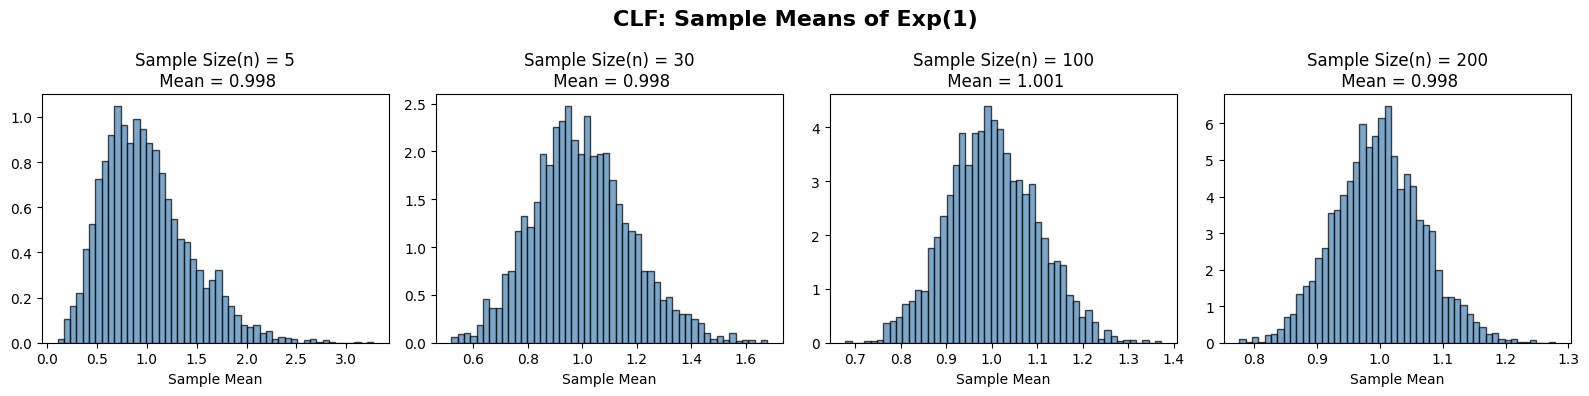

In [20]:
#--- CENTRAL LIMIT THEOREM ---
sample_sizes = [5, 30, 100, 200]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, n in enumerate(sample_sizes):
  means = [np.mean(np.random.exponential(1, n)) for _ in range(3000)]
  axes[i].hist(means, bins=50, density=True, color='steelblue', edgecolor='black', alpha=0.7)
  axes[i].set_title(f'Sample Size(n) = {n}\n Mean = {np.mean(means):.3f}') # SD = {np.std(means):.4f}')
  axes[i].set_xlabel('Sample Mean')

fig.suptitle('CLF: Sample Means of Exp(1)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()